# 05 · Product Recommendations (Objective 5)

**Customer Churn Prediction, Segmentation and Retention Framework · Online Retail II**

This notebook builds personalised product recommendations that the retention framework (Objective 6) can use as the *content* of a win-back or loyalty offer.

**What it does**

1. Rebuilds the same time-based setup as the churn notebooks (cut-off **1 July 2011**, 150-day outcome window, customers active in the previous 365 days).
2. Builds four recommenders and compares them on purchases made **after** the cut-off:
   * **Popularity** – baseline: recommend what most customers buy.
   * **Association rules** – *basket-level*: "baskets with A usually also contain B" (support, confidence, lift).
   * **Item-based collaborative filtering** – *customer-level*: items bought by the same customers are similar.
   * **Matrix factorisation (TruncatedSVD)** – *customer-level*: latent taste factors.
3. Tunes each method on **earlier** snapshots only (2010-07-01 and 2011-01-01), so the test snapshot is used once.
4. Reports Precision@10, Recall@10, Hit rate@10, NDCG@10 and catalogue coverage, with bootstrap 95% confidence intervals.
5. Saves top-10 recommendations per customer for Objective 6 and the dashboard.

**Reads:** `data/clean_sales.csv`, `data/product_lookup.csv`, `data/churn_predictions_test.csv`
**Writes:** `data/recommendations_test_snapshot.csv`, `data/recommendations_current.csv`, `data/recommender_comparison.csv`, `data/recommender_validation.csv`, `data/association_rules.csv`, `recommendation_summary.txt`, charts in `figures/`

**Requirements:** only `pandas numpy scipy scikit-learn matplotlib` (the same as notebooks 01–04). Optional: `mlxtend` for the FP-Growth cell in section 9.

## 1. Setup and settings

In [1]:
import ast
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)

SEED = 42
DATA, FIG = Path("data"), Path("figures")
DATA.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)

# --- Same definitions as notebooks 03 and 04 ---------------------------------
HORIZON_DAYS = 150                       # outcome window after a cut-off
LOOKBACK_DAYS = 365                      # customer must have bought in this window before the cut-off
TEST_CUTOFF = pd.Timestamp("2011-07-01")  # churn test snapshot

# --- Recommender settings ----------------------------------------------------
K = 10                                   # recommendations per customer
KMAX = 20                                # used for the Precision/Recall-vs-K curves
# Tuning snapshots: both outcome windows end BEFORE the test cut-off, so no test data is used for tuning.
VAL_CUTOFFS = [pd.Timestamp("2010-07-01"), pd.Timestamp("2011-01-01")]

# Orders cancelled in full (notebook 02 removes the same three very large orders).
CANCELLED_IN_FULL = [541431, 556444, 581483]

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Load the data

`clean_sales.csv` holds real sales only (returns are in `clean_returns.csv`, which this notebook does not need). The three huge orders that were cancelled in full are removed, exactly as in notebook 02, because a product that was bought and fully cancelled is not a real purchase signal.

In [2]:
sales = pd.read_csv(DATA / "clean_sales.csv", parse_dates=["InvoiceDate"], dtype={"StockCode": str})
lookup = pd.read_csv(DATA / "product_lookup.csv", dtype={"StockCode": str})
churn = pd.read_csv(DATA / "churn_predictions_test.csv")
name_of = dict(zip(lookup["StockCode"], lookup["Description"]))

print("Orders cancelled in full (removed):")
display(sales.loc[sales["Invoice"].isin(CANCELLED_IN_FULL),
                  ["Invoice", "StockCode", "Description", "Quantity", "Price", "CustomerID", "InvoiceDate"]])
sales = sales[~sales["Invoice"].isin(CANCELLED_IN_FULL)].copy()

print(f"\nSales lines     : {len(sales):,}")
print(f"Orders          : {sales['Invoice'].nunique():,}")
print(f"Customers       : {sales['CustomerID'].nunique():,}")
print(f"Products        : {sales['StockCode'].nunique():,}")
print(f"Date range      : {sales['InvoiceDate'].min():%Y-%m-%d} to {sales['InvoiceDate'].max():%Y-%m-%d}")
print(f"Churn test rows : {len(churn):,} customers at snapshot {churn['SnapshotDate'].iloc[0]}")

Orders cancelled in full (removed):


,Invoice,StockCode,Description,Quantity,Price,CustomerID,InvoiceDate
421802,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346,2011-01-18 10:01:00
538375,556444,22502,PICNIC BASKET WICKER SMALL,60,649.50,15098,2011-06-10 15:28:00
776114,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446,2011-12-09 09:15:00



Sales lines     : 776,572
Orders          : 36,591
Customers       : 5,852
Products        : 4,618
Date range      : 2009-12-01 to 2011-12-09
Churn test rows : 4,313 customers at snapshot 2011-07-01


## 3. Time-based snapshots (no leakage)

A **snapshot** at a cut-off date splits the data like the churn notebooks do:

* **Train** = every purchase *before* the cut-off. All recommenders learn only from this.
* **Customers to recommend for (eligible)** = customers who bought in the 365 days before the cut-off. For the test snapshot this must be exactly the 4,313 customers in `churn_predictions_test.csv`; the check below enforces it.
* **Hold-out** = what those customers actually bought in the 150 days *after* the cut-off. Used only for scoring.

Two evaluation settings are reported, because wholesale customers re-order a lot:

| Setting | Recommend | Counts as a hit |
|---|---|---|
| **Discovery** (main) | only products the customer has **never** bought before | a never-before-bought product they bought in the window (cross-sell) |
| **All items** | any product, repeats allowed | any product they bought in the window |

Discovery is the fair test of a recommender and is what a "tailored offer" needs. "All items" is shown for completeness and includes a *re-order favourites* baseline.

In [3]:
def active_customers(sales, cutoff):
    """Customers with at least one purchase in the LOOKBACK_DAYS before the cut-off."""
    cutoff = pd.Timestamp(cutoff)
    recent = sales[(sales["InvoiceDate"] < cutoff) &
                   (sales["InvoiceDate"] >= cutoff - pd.Timedelta(days=LOOKBACK_DAYS))]
    return np.sort(recent["CustomerID"].unique())


class Snapshot:
    """Everything the recommenders need for one cut-off date (train data only, plus the hold-out)."""

    def __init__(self, sales, cutoff, eligible=None, with_holdout=True):
        self.cutoff = pd.Timestamp(cutoff)
        train = sales[sales["InvoiceDate"] < self.cutoff]
        self.n_train_lines = len(train)

        self.eligible = np.sort(np.asarray(active_customers(sales, cutoff) if eligible is None else eligible))
        self.items = np.sort(train["StockCode"].unique())
        self.item_ix = {c: i for i, c in enumerate(self.items)}
        self.custs = np.sort(train["CustomerID"].unique())
        self.cust_ix = {c: i for i, c in enumerate(self.custs)}
        n_c, n_i = len(self.custs), len(self.items)

        # customer x item matrices: bought at all (binary) and number of orders containing the item
        ci = (train.groupby(["CustomerID", "StockCode"])["Invoice"].nunique().rename("n").reset_index())
        r = ci["CustomerID"].map(self.cust_ix).to_numpy()
        c = ci["StockCode"].map(self.item_ix).to_numpy()
        self.U = sparse.csr_matrix((np.ones(len(ci), dtype=np.float32), (r, c)), shape=(n_c, n_i))
        self.Ucount = sparse.csr_matrix((ci["n"].to_numpy(dtype=np.float32), (r, c)), shape=(n_c, n_i))

        # basket x item matrix (one basket = one invoice) for association rules
        inv = train[["Invoice", "StockCode"]].drop_duplicates()
        basket_ix = {v: i for i, v in enumerate(inv["Invoice"].unique())}
        self.B = sparse.csr_matrix(
            (np.ones(len(inv), dtype=np.float32),
             (inv["Invoice"].map(basket_ix).to_numpy(), inv["StockCode"].map(self.item_ix).to_numpy())),
            shape=(len(basket_ix), n_i))

        # eligible customers only
        rows = [self.cust_ix[x] for x in self.eligible]
        self.Ue = self.U[rows]
        self.Ucount_e = self.Ucount[rows]
        self.seen = self.Ue.toarray() > 0                      # already bought before the cut-off
        self.pop = np.asarray(self.U.sum(axis=0)).ravel()      # number of customers who bought each item
        self.cache = {}

        self.truth = None
        if with_holdout:
            end = self.cutoff + pd.Timedelta(days=HORIZON_DAYS)
            fut = sales[(sales["InvoiceDate"] >= self.cutoff) & (sales["InvoiceDate"] < end)]
            fut = (fut[fut["CustomerID"].isin(self.eligible)][["CustomerID", "StockCode"]].drop_duplicates())
            in_cat = fut["StockCode"].isin(self.item_ix)
            self.n_holdout_pairs = len(fut)
            self.n_holdout_uncatalogued = int((~in_cat).sum())  # products never sold before the cut-off
            fut = fut[in_cat]
            row_of = {x: i for i, x in enumerate(self.eligible)}
            self.truth = np.zeros((len(self.eligible), n_i), dtype=bool)
            self.truth[fut["CustomerID"].map(row_of).to_numpy(), fut["StockCode"].map(self.item_ix).to_numpy()] = True
            self.n_holdout_repeat = int((self.truth & self.seen).sum())
            self.n_holdout_new = int((self.truth & ~self.seen).sum())

    def holdout_matrix(self, exclude_seen):
        """Ground truth: new products only (discovery) or all products (repeats allowed)."""
        return self.truth & ~self.seen if exclude_seen else self.truth


# --- the eligible set must be identical to the churn test set ----------------
rule_based = active_customers(sales, TEST_CUTOFF)
assert set(rule_based) == set(churn["CustomerID"]), "Eligible customers differ from churn_predictions_test.csv"
print(f"Eligible customers at {TEST_CUTOFF:%Y-%m-%d}: {len(rule_based):,} = churn test customers  ✓")

test_snap = Snapshot(sales, TEST_CUTOFF, eligible=churn["CustomerID"].to_numpy())
tot = test_snap.n_holdout_pairs
print(f"\nTest snapshot {TEST_CUTOFF:%Y-%m-%d}")
print(f"  Training lines        : {test_snap.n_train_lines:,}")
print(f"  Baskets (orders)      : {test_snap.B.shape[0]:,}")
print(f"  Catalogue (products)  : {len(test_snap.items):,}")
print(f"  Customers in training : {len(test_snap.custs):,}  (all customers seen before the cut-off)")
print(f"  Matrix density        : {test_snap.U.nnz / (test_snap.U.shape[0] * test_snap.U.shape[1]):.2%}")

has_future = test_snap.truth.any(axis=1)
print(f"\nHold-out (next {HORIZON_DAYS} days): {has_future.sum():,} of {len(test_snap.eligible):,} customers bought something "
      f"({has_future.mean():.1%}); the other {(~has_future).sum():,} are the churners and cannot be scored.")
print(f"  Distinct (customer, product) purchases in hold-out : {tot:,}")
print(f"    re-orders of a product bought before             : {test_snap.n_holdout_repeat / tot:.1%}")
print(f"    new to the customer, product already in catalogue: {test_snap.n_holdout_new / tot:.1%}")
print(f"    brand-new products (not sold before cut-off)     : {test_snap.n_holdout_uncatalogued / tot:.1%}  (cannot be recommended)")

Eligible customers at 2011-07-01: 4,313 = churn test customers  ✓

Test snapshot 2011-07-01
  Training lines        : 555,394
  Baskets (orders)      : 26,944
  Catalogue (products)  : 4,335
  Customers in training : 5,016  (all customers seen before the cut-off)
  Matrix density        : 1.65%

Hold-out (next 150 days): 2,343 of 4,313 customers bought something (54.3%); the other 1,970 are the churners and cannot be scored.
  Distinct (customer, product) purchases in hold-out : 117,771
    re-orders of a product bought before             : 35.7%
    new to the customer, product already in catalogue: 51.5%
    brand-new products (not sold before cut-off)     : 12.8%  (cannot be recommended)


## 4. The recommenders

Every recommender is a **scorer**: given a block of customers it returns a score for every product, and the top-K highest-scoring products become the recommendations. Scoring in blocks keeps memory low.

### 4.1 Popularity (baseline)
Score = number of customers who bought the product before the cut-off. Everybody gets the same list (minus what they already bought). Any useful method must beat this.

### 4.2 Association rules (basket-level)
A rule **A → B** says "baskets that contain A often contain B". It is judged by three numbers:

* **support** = share of all baskets containing both A and B
* **confidence** = share of baskets with A that also contain B
* **lift** = confidence ÷ (share of baskets containing B). Lift above 1 means A and B appear together *more* than chance.

Rules with a single item on each side are mined from every training order by counting co-occurrences with sparse matrices (this is exactly what Apriori / FP-Growth compute for itemsets of size 2, and needs no extra library). A customer's score for product B is the sum of rule weights **A → B** over everything A they have bought. Rules are filtered by minimum support and confidence and must have lift above 1. The weight (confidence or lift) and the thresholds are tuned in section 5.

### 4.3 Item-based collaborative filtering (customer-level)
Two products are **similar** when largely the same customers buy them (cosine similarity on the customer × product matrix). Each product keeps only its most similar neighbours. A customer's score for product B is the sum of similarities between B and the products they bought.

### 4.4 Matrix factorisation (customer-level)
TruncatedSVD compresses the customer × product matrix into a few latent "taste" factors. Reconstructing each customer's row from those factors gives a score for products they have not bought yet.

### 4.5 Re-order favourites (only in the *All items* setting)
Score = how many orders contained the product. This shows how much of the "All items" result is simply customers re-ordering their usual lines.

In [4]:
# ---------------------------------------------------------------- association rules
def pair_stats(snap, support_floor=0.002):
    """Support, confidence and lift of every rule A -> B (one item each side) seen in training orders."""
    B, n_baskets = snap.B, snap.B.shape[0]
    C = (B.T @ B).tocoo()                                  # co-occurrence counts
    n_item = np.asarray(B.sum(axis=0)).ravel()             # baskets containing each item
    keep = (C.row != C.col) & (C.data / n_baskets >= support_floor)
    a, b, n_ab = C.row[keep], C.col[keep], C.data[keep]
    confidence = n_ab / n_item[a]
    lift = confidence / (n_item[b] / n_baskets)
    return {"a": a, "b": b, "support": n_ab / n_baskets, "confidence": confidence, "lift": lift}


def get_pair_stats(snap):
    if "pairs" not in snap.cache:
        snap.cache["pairs"] = pair_stats(snap)
    return snap.cache["pairs"]


def rule_matrix(snap, min_support, min_confidence, weight):
    st = get_pair_stats(snap)
    m = (st["support"] >= min_support) & (st["confidence"] >= min_confidence) & (st["lift"] > 1)
    w = st[weight][m]
    n = len(snap.items)
    return sparse.csr_matrix((w, (st["a"][m], st["b"][m])), shape=(n, n))


# ---------------------------------------------------------------- item-item collaborative filtering
def get_similarity(snap):
    if "sim" not in snap.cache:
        Un = normalize(snap.U, axis=0)                      # unit-length product columns
        S = (Un.T @ Un).toarray().astype(np.float32)        # cosine similarity between products
        np.fill_diagonal(S, 0)
        snap.cache["sim"] = S
    return snap.cache["sim"]


def keep_neighbours(S, n_neighbours):
    idx = np.argpartition(-S, n_neighbours, axis=1)[:, :n_neighbours]
    rows = np.arange(S.shape[0])[:, None]
    out = np.zeros_like(S)
    out[rows, idx] = S[rows, idx]
    return sparse.csr_matrix(out)


# ---------------------------------------------------------------- matrix factorisation
def get_svd(snap, components):
    key = ("svd", components)
    if key not in snap.cache:
        snap.cache[key] = TruncatedSVD(n_components=components, random_state=SEED).fit(snap.U)
    return snap.cache[key]


# ---------------------------------------------------------------- scorer factory
def build_scorer(snap, family, params=None):
    """Return scorer(rows) -> (len(rows) x n_items) score matrix for a slice of eligible customers."""
    params = params or {}
    n = len(snap.items)
    if family == "Popularity":
        return lambda rows: np.broadcast_to(snap.pop, (rows.stop - rows.start, n))
    if family == "Re-order favourites":
        return lambda rows: snap.Ucount_e[rows].toarray()
    if family == "Association rules":
        R = rule_matrix(snap, params["min_support"], params["min_confidence"], params["weight"])
        return lambda rows: (snap.Ue[rows] @ R).toarray()
    if family == "Item-based CF":
        S = keep_neighbours(get_similarity(snap), params["neighbours"])
        return lambda rows: (snap.Ue[rows] @ S).toarray()
    if family == "Matrix factorisation (SVD)":
        svd = get_svd(snap, params["components"])
        return lambda rows: svd.transform(snap.Ue[rows]) @ svd.components_
    raise ValueError(family)


def recommend_top(snap, scorer, exclude_seen, kmax=KMAX, block=1000):
    """Top-kmax product indices (and scores) for every eligible customer."""
    n_cust = len(snap.eligible)
    tops = np.zeros((n_cust, kmax), dtype=np.int32)
    vals = np.zeros((n_cust, kmax))
    tie = 1e-6 * snap.pop / snap.pop.max()                 # popularity only breaks exact ties
    for a in range(0, n_cust, block):
        b = min(a + block, n_cust)
        S = np.asarray(scorer(slice(a, b)), dtype=np.float64) + tie
        if exclude_seen:
            S[snap.seen[a:b]] = -np.inf
        idx = np.argpartition(-S, kmax, axis=1)[:, :kmax]
        r = np.arange(b - a)[:, None]
        idx = idx[r, np.argsort(-S[r, idx], axis=1, kind="stable")]
        tops[a:b] = idx
        vals[a:b] = S[r, idx] - tie[idx]
    return tops, vals

## 5. Evaluation metrics

For each customer who has at least one hit-able product in the hold-out, with the top-K list:

* **Precision@K** – share of the K recommendations the customer actually bought.
* **Recall@K** – share of the customer's hold-out products that were in the K recommendations.
* **Hit rate@K** – share of customers with at least one correct recommendation.
* **NDCG@K** – like precision but rewards correct items placed higher in the list.
* **Coverage** – share of the catalogue that appears in anybody's top-K (higher = less repetitive).

Uncertainty is shown with a bootstrap 95% confidence interval over customers (1,000 resamples); differences between methods are also bootstrapped (paired).

In [5]:
def metrics_from_top(snap, tops, exclude_seen, k=K):
    """Per-customer metrics for the first k recommendations. Returns (dict of arrays, valid mask)."""
    truth = snap.holdout_matrix(exclude_seen)
    n_truth = truth.sum(axis=1)
    valid = n_truth > 0                                    # customers that can be scored
    top = tops[:, :k]
    hit = truth[np.arange(len(top))[:, None], top]
    discount = 1.0 / np.log2(np.arange(2, k + 2))
    ideal = np.cumsum(discount)[np.clip(np.minimum(n_truth, k) - 1, 0, None)]
    m = {"precision": hit.mean(axis=1),
         "recall": hit.sum(axis=1) / np.maximum(n_truth, 1),
         "hit_rate": hit.any(axis=1).astype(float),
         "ndcg": (hit * discount).sum(axis=1) / ideal}
    m = {name: v[valid] for name, v in m.items()}
    m["coverage"] = np.unique(top[valid]).size / len(snap.items)
    return m, valid


def boot_ci(x, n_boot=1000, seed=SEED):
    """Bootstrap 95% CI of the mean."""
    g = np.random.default_rng(seed)
    idx = g.integers(0, len(x), size=(n_boot, len(x)))
    means = x[idx].mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


def fmt_ci(x):
    lo, hi = boot_ci(x)
    return f"{x.mean():.3f} [{lo:.3f}, {hi:.3f}]"


def evaluate_families(snap, families, exclude_seen):
    """families: {name: (family, params)} -> {name: dict(tops, vals, metrics, valid)}"""
    out = {}
    for name, (fam, params) in families.items():
        tops, vals = recommend_top(snap, build_scorer(snap, fam, params), exclude_seen)
        m, valid = metrics_from_top(snap, tops, exclude_seen)
        out[name] = {"tops": tops, "vals": vals, "m": m, "valid": valid}
    return out


def results_table(res, baseline="Popularity"):
    rows = []
    base = res[baseline]["m"]["precision"]
    for name, r in res.items():
        m = r["m"]
        diff = m["precision"] - base
        rows.append({"Method": name,
                     "Precision@10 [95% CI]": fmt_ci(m["precision"]),
                     "Recall@10": m["recall"].mean(),
                     "Hit rate@10": m["hit_rate"].mean(),
                     "NDCG@10": m["ndcg"].mean(),
                     "Coverage": m["coverage"],
                     "Precision gain vs popularity [95% CI]": "-" if name == baseline else
                         f"{diff.mean():+.3f} [{boot_ci(diff)[0]:+.3f}, {boot_ci(diff)[1]:+.3f}]"})
    return pd.DataFrame(rows).set_index("Method")

## 6. Tune on earlier snapshots (not on the test snapshot)

Each method has a few settings. They are chosen by Precision@10 in the **discovery** setting, **averaged over two earlier snapshots** (1 July 2010 and 1 January 2011). Using one snapshot in each half of the year avoids tuning to a single season. Both outcome windows end before 1 July 2011, so nothing from the test period is used.

| Method | Settings searched |
|---|---|
| Association rules | minimum support {0.2%, 0.5%, 1%} × minimum confidence {0.1, 0.2, 0.3} × rule weight {confidence, lift} |
| Item-based CF | neighbours per product {10, 20, 50, 100} |
| Matrix factorisation | latent factors {16, 32, 64, 128} |

In [6]:
val_snaps = [Snapshot(sales, c) for c in VAL_CUTOFFS]
for s, c in zip(val_snaps, VAL_CUTOFFS):
    print(f"Tuning snapshot {c:%Y-%m-%d}: {len(s.eligible):,} eligible customers, {s.B.shape[0]:,} training baskets, "
          f"{len(s.items):,} products, {int(s.holdout_matrix(True).any(axis=1).sum()):,} customers with a new product in the hold-out")

grids = {
    "Association rules": [dict(min_support=s, min_confidence=c, weight=w)
                          for s in (0.002, 0.005, 0.01) for c in (0.1, 0.2, 0.3) for w in ("confidence", "lift")],
    "Item-based CF": [dict(neighbours=n) for n in (10, 20, 50, 100)],
    "Matrix factorisation (SVD)": [dict(components=n) for n in (16, 32, 64, 128)],
}

def val_precision(family, params):
    scores = []
    for snap in val_snaps:
        tops, _ = recommend_top(snap, build_scorer(snap, family, params), exclude_seen=True)
        m, _ = metrics_from_top(snap, tops, True)
        scores.append(m["precision"].mean())
    return scores

records = [{"family": "Popularity", "params": "{}", "val_2010-07": s[0], "val_2011-01": s[1], "val_mean": np.mean(s)}
           for s in [val_precision("Popularity", {})]]
for family, grid in grids.items():
    for params in grid:
        s = val_precision(family, params)
        records.append({"family": family, "params": str(params), "val_2010-07": s[0], "val_2011-01": s[1], "val_mean": np.mean(s)})

validation = pd.DataFrame(records).sort_values(["family", "val_mean"], ascending=[True, False]).reset_index(drop=True)
validation.to_csv(DATA / "recommender_validation.csv", index=False)

print("\nBest 3 settings per method (validation Precision@10, discovery setting):")
display(validation.groupby("family").head(3).round(4))

chosen = {}
for family, grid in grids.items():
    best = validation[validation["family"] == family].iloc[0]
    chosen[family] = ast.literal_eval(best["params"])
print("\nChosen settings:")
for fam, p in chosen.items():
    print(f"  {fam:28s} {p}")

del val_snaps                                   # free memory

Tuning snapshot 2010-07-01: 2,951 eligible customers, 9,217 training baskets, 3,623 products, 1,906 customers with a new product in the hold-out
Tuning snapshot 2011-01-01: 4,205 eligible customers, 19,586 training baskets, 4,016 products, 1,763 customers with a new product in the hold-out

Best 3 settings per method (validation Precision@10, discovery setting):


,family,params,val_2010-07,val_2011-01,val_mean
0,Association rules,"{'min_support': 0.005, 'min_confidence': 0.2, 'weight': ...",0.1241,0.0792,0.1016
1,Association rules,"{'min_support': 0.002, 'min_confidence': 0.2, 'weight': ...",0.1230,0.0758,0.0994
2,Association rules,"{'min_support': 0.005, 'min_confidence': 0.1, 'weight': ...",0.1189,0.0793,0.0991
18,Item-based CF,{'neighbours': 20},0.1235,0.0833,0.1034
19,Item-based CF,{'neighbours': 10},0.1220,0.0842,0.1031
20,Item-based CF,{'neighbours': 50},0.1152,0.0809,0.0981
22,Matrix factorisation (SVD),{'components': 64},0.1278,0.0870,0.1074
23,Matrix factorisation (SVD),{'components': 32},0.1284,0.0851,0.1068
24,Matrix factorisation (SVD),{'components': 16},0.1232,0.0826,0.1029
26,Popularity,{},0.0720,0.0548,0.0634



Chosen settings:
  Association rules            {'min_support': 0.005, 'min_confidence': 0.2, 'weight': 'confidence'}
  Item-based CF                {'neighbours': 20}
  Matrix factorisation (SVD)   {'components': 64}


## 7. Final test on the 1 July 2011 snapshot

The tuned models are trained on purchases before 1 July 2011 and scored **once** on what customers bought in the following 150 days. Only customers who bought something in that window (and, in the discovery setting, bought at least one product that was new to them) can be scored.

In [7]:
families_discovery = {
    "Popularity": ("Popularity", {}),
    "Association rules": ("Association rules", chosen["Association rules"]),
    "Item-based CF": ("Item-based CF", chosen["Item-based CF"]),
    "Matrix factorisation (SVD)": ("Matrix factorisation (SVD)", chosen["Matrix factorisation (SVD)"]),
}
families_all = {"Re-order favourites": ("Re-order favourites", {}), **families_discovery}

res_new = evaluate_families(test_snap, families_discovery, exclude_seen=True)
res_all = evaluate_families(test_snap, families_all, exclude_seen=False)

n_new = int(res_new["Popularity"]["valid"].sum())
n_all = int(res_all["Popularity"]["valid"].sum())

print(f"DISCOVERY setting - recommend products the customer has never bought  ({n_new:,} customers scored)")
tab_new = results_table(res_new)
display(tab_new.round(3))

print(f"\nALL-ITEMS setting - repeats allowed  ({n_all:,} customers scored)")
tab_all = results_table(res_all)
display(tab_all.round(3))

comparison = pd.concat([tab_new.assign(Setting="Discovery (new products only)", Customers_scored=n_new),
                        tab_all.assign(Setting="All items (repeats allowed)", Customers_scored=n_all)]).reset_index()
comparison.to_csv(DATA / "recommender_comparison.csv", index=False)

DISCOVERY setting - recommend products the customer has never bought  (2,243 customers scored)


,Precision@10 [95% CI],Recall@10,Hit rate@10,NDCG@10,Coverage,Precision gain vs popularity [95% CI]
Method,,,,,,
Popularity,"0.049 [0.046, 0.053]",0.022,0.342,0.053,0.018,-
Association rules,"0.073 [0.069, 0.078]",0.040,0.430,0.084,0.096,"+0.024 [+0.019, +0.028]"
Item-based CF,"0.084 [0.079, 0.089]",0.047,0.458,0.096,0.248,"+0.035 [+0.030, +0.039]"
Matrix factorisation (SVD),"0.087 [0.082, 0.092]",0.048,0.483,0.101,0.197,"+0.037 [+0.033, +0.042]"



ALL-ITEMS setting - repeats allowed  (2,343 customers scored)


,Precision@10 [95% CI],Recall@10,Hit rate@10,NDCG@10,Coverage,Precision gain vs popularity [95% CI]
Method,,,,,,
Re-order favourites,"0.352 [0.340, 0.364]",0.151,0.855,0.408,0.404,"+0.226 [+0.216, +0.236]"
Popularity,"0.126 [0.120, 0.133]",0.039,0.617,0.137,0.002,-
Association rules,"0.222 [0.212, 0.231]",0.078,0.684,0.240,0.092,"+0.095 [+0.087, +0.103]"
Item-based CF,"0.234 [0.224, 0.244]",0.083,0.693,0.252,0.286,"+0.108 [+0.099, +0.117]"
Matrix factorisation (SVD),"0.283 [0.273, 0.293]",0.112,0.801,0.319,0.147,"+0.157 [+0.148, +0.166]"


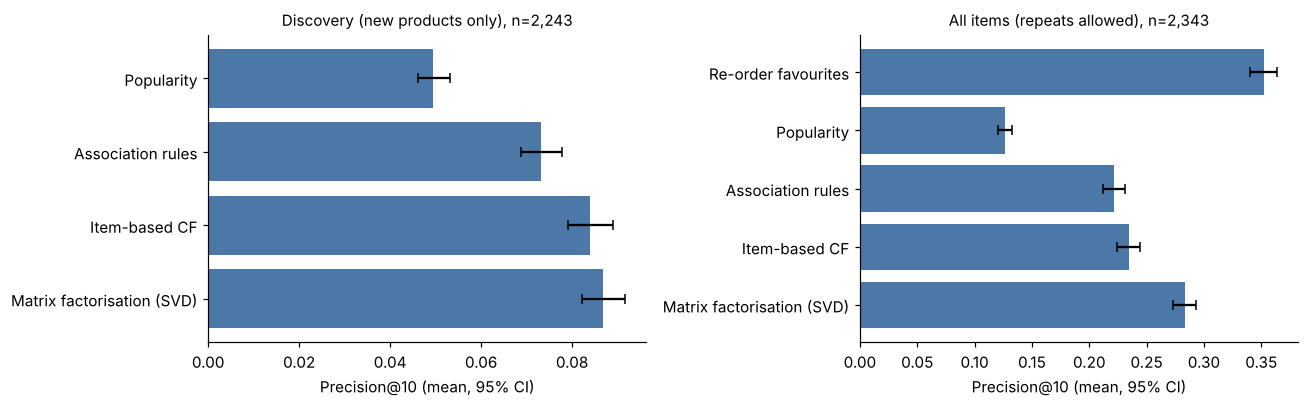

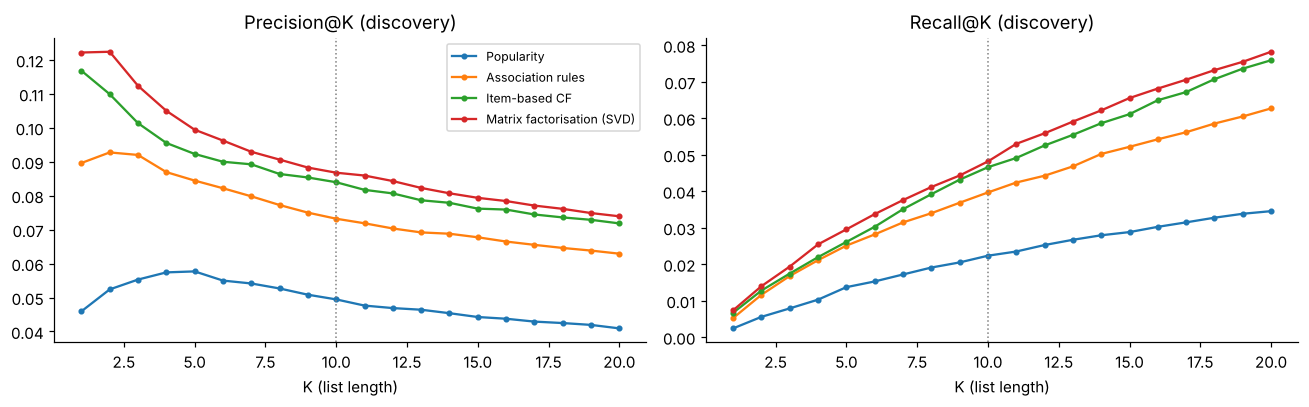

In [8]:
# ---- Chart 1: Precision@10 with 95% CI, both settings
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=False)
for ax, res, title in [(axes[0], res_new, f"Discovery (new products only), n={n_new:,}"),
                       (axes[1], res_all, f"All items (repeats allowed), n={n_all:,}")]:
    names = list(res)[::-1]
    means = [res[n]["m"]["precision"].mean() for n in names]
    cis = np.array([boot_ci(res[n]["m"]["precision"]) for n in names])
    ax.barh(names, means, xerr=[np.array(means) - cis[:, 0], cis[:, 1] - np.array(means)], color="#4C78A8", capsize=3)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Precision@10 (mean, 95% CI)")
plt.tight_layout()
plt.savefig(FIG / "rec_precision_comparison.png", bbox_inches="tight")
plt.show()

# ---- Chart 2: Precision@K and Recall@K as K grows (discovery setting)
ks = list(range(1, KMAX + 1))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, r in res_new.items():
    p = [metrics_from_top(test_snap, r["tops"], True, k)[0]["precision"].mean() for k in ks]
    rc = [metrics_from_top(test_snap, r["tops"], True, k)[0]["recall"].mean() for k in ks]
    axes[0].plot(ks, p, marker="o", ms=3, label=name)
    axes[1].plot(ks, rc, marker="o", ms=3, label=name)
axes[0].set_title("Precision@K (discovery)"); axes[1].set_title("Recall@K (discovery)")
for ax in axes:
    ax.set_xlabel("K (list length)"); ax.axvline(K, color="grey", ls=":", lw=1)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "rec_metrics_by_k.png", bbox_inches="tight")
plt.show()

### 7.1 Where do the recommendations work best?

The best method is picked from the **validation** results (section 6), not from the test results. Below it is compared with the popularity baseline for different customer groups. Note that a customer who churned (bought nothing in the 150 days) cannot be scored, so these tables describe customers who *did* return; the high-risk groups are therefore smaller and are the customers the model got "wrong" (they were predicted to churn but came back).

Validation Precision@10 of the best setting of each method:


,val_mean
family,
Matrix factorisation (SVD),0.1074
Item-based CF,0.1034
Association rules,0.1016



Selected method (by validation): Matrix factorisation (SVD)
Best method on the test snapshot  : Matrix factorisation (SVD)

Paired bootstrap of Precision@10 (discovery): Matrix factorisation (SVD) minus each other method
  vs Association rules            +0.0136  [+0.0093, +0.0181]  -> clear difference
  vs Item-based CF                +0.0028  [-0.0012, +0.0068]  -> difference could be chance

By churn risk tier (from notebook 04):


,Customers scored,Matrix factorisation (SVD) P@10,Popularity P@10,Matrix factorisation (SVD) hit rate@10
Group,,,,
Low,1554,0.090,0.049,0.487
Medium,449,0.083,0.051,0.477
High,240,0.072,0.049,0.467



By purchase history (distinct products bought before the cut-off):


,Customers scored,Matrix factorisation (SVD) P@10,Popularity P@10,Matrix factorisation (SVD) hit rate@10
Group,,,,
1-9,105,0.041,0.029,0.305
10-49,708,0.075,0.043,0.436
50-199,1104,0.091,0.050,0.503
200+,326,0.112,0.069,0.574


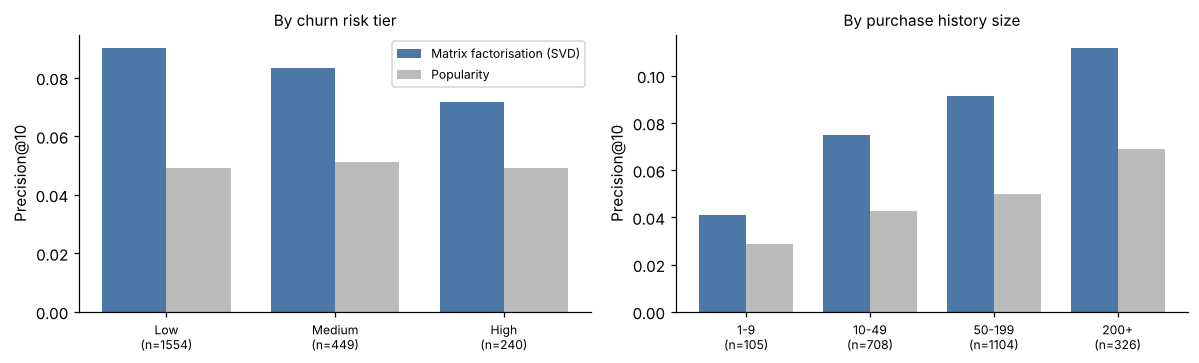

In [9]:
model_names = [n for n in families_discovery if n != "Popularity"]
val_best = validation[validation["family"].isin(model_names)].groupby("family")["val_mean"].max().sort_values(ascending=False)
winner = val_best.index[0]
print("Validation Precision@10 of the best setting of each method:")
display(val_best.round(4).to_frame("val_mean"))
print(f"\nSelected method (by validation): {winner}")
test_best = max(model_names, key=lambda n: res_new[n]["m"]["precision"].mean())
print(f"Best method on the test snapshot  : {test_best}" + ("" if test_best == winner else "   (differs from validation choice)"))

print(f"\nPaired bootstrap of Precision@10 (discovery): {winner} minus each other method")
for other in model_names:
    if other == winner:
        continue
    d = res_new[winner]["m"]["precision"] - res_new[other]["m"]["precision"]
    lo, hi = boot_ci(d)
    verdict = "clear difference" if (lo > 0 or hi < 0) else "difference could be chance"
    print(f"  vs {other:28s} {d.mean():+.4f}  [{lo:+.4f}, {hi:+.4f}]  -> {verdict}")

valid = res_new[winner]["valid"]
tier = churn.set_index("CustomerID").loc[test_snap.eligible, "RiskTier"].to_numpy()
history = np.asarray(test_snap.Ue.sum(axis=1)).ravel()          # distinct products bought before the cut-off
band = pd.cut(history, bins=[0, 9, 49, 199, np.inf], labels=["1-9", "10-49", "50-199", "200+"])

def breakdown(groups, labels):
    rows = []
    for g in labels:
        sel = (groups == g)[valid]
        if sel.sum() == 0:
            continue
        rows.append({"Group": g, "Customers scored": int(sel.sum()),
                     f"{winner} P@10": res_new[winner]["m"]["precision"][sel].mean(),
                     "Popularity P@10": res_new["Popularity"]["m"]["precision"][sel].mean(),
                     f"{winner} hit rate@10": res_new[winner]["m"]["hit_rate"][sel].mean()})
    return pd.DataFrame(rows).set_index("Group")

print("\nBy churn risk tier (from notebook 04):")
by_tier = breakdown(tier, ["Low", "Medium", "High"])
display(by_tier.round(3))
print("\nBy purchase history (distinct products bought before the cut-off):")
by_band = breakdown(np.asarray(band, dtype=object), ["1-9", "10-49", "50-199", "200+"])
display(by_band.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, tab, title in [(axes[0], by_tier, "By churn risk tier"), (axes[1], by_band, "By purchase history size")]:
    x = np.arange(len(tab)); w = 0.38
    ax.bar(x - w / 2, tab[f"{winner} P@10"].values, w, label=winner, color="#4C78A8")
    ax.bar(x + w / 2, tab["Popularity P@10"].values, w, label="Popularity", color="#BBBBBB")
    ax.set_xticks(x); ax.set_xticklabels([f"{i}\n(n={n})" for i, n in zip(tab.index, tab["Customers scored"])], fontsize=8)
    ax.set_title(title, fontsize=10); ax.set_ylabel("Precision@10")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "rec_precision_by_group.png", bbox_inches="tight")
plt.show()

## 8. What the association rules say

The rules below are mined from the training baskets before 1 July 2011 with the settings chosen in section 6. Sorted by **lift**, they show which products are bought together far more often than chance. They are also useful for the report on their own, since they explain *why* a product is recommended ("customers who buy A also buy B"). Many of the strongest rules link colour or size variants of the same product family (for example the herb markers); that is expected for gift-ware, and it means a high lift does not always make a *useful* cross-sell.

Settings: {'min_support': 0.005, 'min_confidence': 0.2, 'weight': 'confidence'}
Rules kept: 1,721   covering 482 products
Median support 0.76%, median confidence 0.35, median lift 10.0

Top 12 rules by lift:


,antecedent_name,consequent_name,support,confidence,lift
0,HERB MARKER ROSEMARY,HERB MARKER THYME,0.005,0.919,168.531006
1,HERB MARKER THYME,HERB MARKER ROSEMARY,0.005,0.932,168.531006
2,HERB MARKER MINT,HERB MARKER PARSLEY,0.005,0.889,164.042999
3,HERB MARKER PARSLEY,HERB MARKER MINT,0.005,0.932,164.042999
4,HERB MARKER ROSEMARY,HERB MARKER BASIL,0.005,0.913,163.955002
5,HERB MARKER BASIL,HERB MARKER ROSEMARY,0.005,0.907,163.955002
6,HERB MARKER MINT,HERB MARKER ROSEMARY,0.005,0.895,161.921997
7,HERB MARKER ROSEMARY,HERB MARKER MINT,0.005,0.919,161.921997
8,HERB MARKER MINT,HERB MARKER BASIL,0.005,0.895,160.841995
9,HERB MARKER BASIL,HERB MARKER MINT,0.005,0.913,160.841995



Top 8 rules by support (the most common pairings):


,antecedent_name,consequent_name,support,confidence,lift
1393,WHITE HANGING HEART T-LIGHT HOLDER,RED HANGING HEART T-LIGHT HOLDER,0.034,0.228,4.765
1394,RED HANGING HEART T-LIGHT HOLDER,WHITE HANGING HEART T-LIGHT HOLDER,0.034,0.715,4.765
1236,PACK OF 72 RETROSPOT CAKE CASES,60 TEATIME FAIRY CAKE CASES,0.029,0.380,6.942
1237,60 TEATIME FAIRY CAKE CASES,PACK OF 72 RETROSPOT CAKE CASES,0.029,0.528,6.942
1250,JUMBO BAG RED RETROSPOT,JUMBO BAG PINK POLKADOT,0.029,0.325,6.686
1251,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,0.029,0.590,6.686
1124,LUNCH BAG PINK POLKADOT,LUNCH BAG RED RETROSPOT,0.028,0.551,7.714
1125,LUNCH BAG RED RETROSPOT,LUNCH BAG PINK POLKADOT,0.028,0.389,7.714


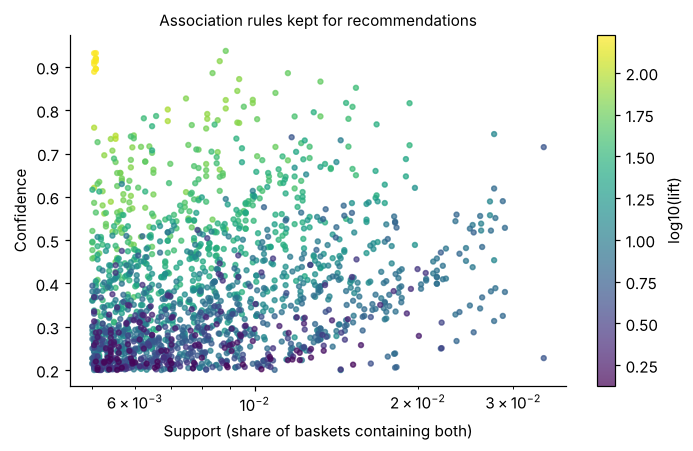

In [10]:
rp = chosen["Association rules"]
st = get_pair_stats(test_snap)
rules = pd.DataFrame({"antecedent": test_snap.items[st["a"]], "consequent": test_snap.items[st["b"]],
                      "support": st["support"], "confidence": st["confidence"], "lift": st["lift"]})
rules = rules[(rules["support"] >= rp["min_support"]) & (rules["confidence"] >= rp["min_confidence"]) & (rules["lift"] > 1)].copy()
rules["antecedent_name"] = rules["antecedent"].map(name_of)
rules["consequent_name"] = rules["consequent"].map(name_of)
rules = rules.sort_values("lift", ascending=False).reset_index(drop=True)
rules.to_csv(DATA / "association_rules.csv", index=False)

print(f"Settings: {rp}")
print(f"Rules kept: {len(rules):,}   covering {pd.unique(rules[['antecedent', 'consequent']].values.ravel()).size:,} products")
print(f"Median support {rules['support'].median():.2%}, median confidence {rules['confidence'].median():.2f}, median lift {rules['lift'].median():.1f}")

print("\nTop 12 rules by lift:")
display(rules.head(12)[["antecedent_name", "consequent_name", "support", "confidence", "lift"]].round(3))

print("\nTop 8 rules by support (the most common pairings):")
display(rules.sort_values("support", ascending=False).head(8)[["antecedent_name", "consequent_name", "support", "confidence", "lift"]].round(3))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
sc = ax.scatter(rules["support"], rules["confidence"], c=np.log10(rules["lift"]), cmap="viridis", s=10, alpha=0.7)
ax.set_xscale("log"); ax.set_xlabel("Support (share of baskets containing both)"); ax.set_ylabel("Confidence")
cb = plt.colorbar(sc, ax=ax); cb.set_label("log10(lift)")
ax.set_title("Association rules kept for recommendations", fontsize=10)
plt.tight_layout()
plt.savefig(FIG / "rec_rules_support_confidence.png", bbox_inches="tight")
plt.show()

## 9. Optional: multi-item rules with FP-Growth

The rules above have one product on each side. This optional cell mines **itemsets of up to 3 products** with FP-Growth from the `mlxtend` library (`pip install mlxtend`) to show rules such as {A, B} → C. It is *not* used for the recommendations or the evaluation, so the notebook works without it; if `mlxtend` is missing the cell prints a message and stops.

In [11]:
try:
    from mlxtend.frequent_patterns import fpgrowth, association_rules

    MIN_SUP = 0.02
    n_baskets = test_snap.B.shape[0]
    n_item = np.asarray(test_snap.B.sum(axis=0)).ravel()
    frequent = np.where(n_item / n_baskets >= MIN_SUP)[0]                  # only frequent items, keeps it fast
    basket_df = pd.DataFrame.sparse.from_spmatrix(test_snap.B[:, frequent].astype(bool),
                                                  columns=[name_of[c] for c in test_snap.items[frequent]])
    itemsets = fpgrowth(basket_df, min_support=MIN_SUP, use_colnames=True, max_len=3)
    try:
        fp_rules = association_rules(itemsets, metric="lift", min_threshold=1.0)
    except TypeError:                                                      # newer mlxtend versions need num_itemsets
        fp_rules = association_rules(itemsets, num_itemsets=len(basket_df), metric="lift", min_threshold=1.0)

    fp_rules["n_antecedent"] = fp_rules["antecedents"].apply(len)
    print(f"{len(itemsets):,} frequent itemsets, {len(fp_rules):,} rules (support >= {MIN_SUP:.0%}); "
          f"{(fp_rules['n_antecedent'] >= 2).sum():,} rules have two products on the left side.")
    show = fp_rules[fp_rules["n_antecedent"] >= 2].sort_values("lift", ascending=False).head(10)
    display(show[["antecedents", "consequents", "support", "confidence", "lift"]]
            .assign(antecedents=lambda d: d["antecedents"].apply(lambda s: " + ".join(sorted(s))),
                    consequents=lambda d: d["consequents"].apply(lambda s: " + ".join(sorted(s)))).round(3))
except ImportError:
    print("mlxtend is not installed - skipping this optional cell (pip install mlxtend).")
except Exception as e:                                                      # optional cell must never stop the notebook
    print("Optional FP-Growth cell skipped:", type(e).__name__, e)

mlxtend is not installed - skipping this optional cell (pip install mlxtend).


## 10. Generate the recommendations for the retention framework

The final recommender is the method chosen by validation in section 7.1. It is trained on all purchases before the cut-off and recommends the **top 10 products the customer has never bought**, with a readable product name and the model score.

Two files are written, both in long format (one row per customer and rank):

* **`recommendations_test_snapshot.csv`** – for the 4,313 customers of the churn test snapshot (1 July 2011). Join on `CustomerID` with `churn_predictions_test.csv`, so every churn-risk customer has recommended products.
* **`recommendations_current.csv`** – retrained on all data up to the end of the dataset (10 Dec 2011) for every customer who bought in the last 365 days. Use this once the retention framework scores today's customers.

Customers who bought nothing in the hold-out window are exactly the churners; their recommendations cannot be validated with this data. Whether the offer would actually win them back is estimated by the simulation in Objective 8.

In [12]:
def recommendations_long(snap, tops, vals, method, k=K):
    n = len(snap.eligible)
    out = pd.DataFrame({
        "CustomerID": np.repeat(snap.eligible, k),
        "SnapshotDate": snap.cutoff.strftime("%Y-%m-%d"),
        "Rank": np.tile(np.arange(1, k + 1), n),
        "StockCode": snap.items[tops[:, :k].ravel()],
        "Score": vals[:, :k].ravel(),
        "Method": method})
    out.insert(4, "Description", out["StockCode"].map(name_of))
    return out


# ---- test snapshot (already trained above)
tops, vals = res_new[winner]["tops"], res_new[winner]["vals"]
recs_test = recommendations_long(test_snap, tops, vals, winner)
recs_test.to_csv(DATA / "recommendations_test_snapshot.csv", index=False)
print(f"Test snapshot : {recs_test['CustomerID'].nunique():,} customers x {K} = {len(recs_test):,} rows -> data/recommendations_test_snapshot.csv")

# ---- current snapshot: everything up to the end of the data
END = sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
cur_snap = Snapshot(sales, END, with_holdout=False)
tops_c, vals_c = recommend_top(cur_snap, build_scorer(cur_snap, winner, chosen[winner]), exclude_seen=True)
recs_cur = recommendations_long(cur_snap, tops_c, vals_c, winner)
recs_cur.to_csv(DATA / "recommendations_current.csv", index=False)
print(f"Current       : {recs_cur['CustomerID'].nunique():,} customers (bought in the last {LOOKBACK_DAYS} days before {END:%Y-%m-%d}) "
      f"-> data/recommendations_current.csv")

assert recs_test.groupby("CustomerID").size().eq(K).all() and recs_cur.groupby("CustomerID").size().eq(K).all()
assert not recs_test.duplicated(["CustomerID", "StockCode"]).any()
# recommended products must be new to the customer
seen_pairs = set(zip(*np.nonzero(test_snap.seen)))
cust_row = {c: i for i, c in enumerate(test_snap.eligible)}
assert not any((cust_row[c], test_snap.item_ix[s]) in seen_pairs for c, s in zip(recs_test["CustomerID"], recs_test["StockCode"]))
print("Checks passed: 10 unique recommendations per customer, none already bought.")

# ---- example: three high-risk customers with a long purchase history
cand = churn[(churn["RiskTier"] == "High")].copy()
cand["history"] = cand["CustomerID"].map(dict(zip(test_snap.eligible, history)))
examples = cand[cand["history"] >= 50].sort_values("ChurnProbability", ascending=False).head(3)["CustomerID"]
print("\nExamples (high churn risk, 50+ products bought):")
for cid in examples:
    mine = sales[(sales["CustomerID"] == cid) & (sales["InvoiceDate"] < TEST_CUTOFF)]
    fav = mine.groupby("StockCode")["Quantity"].sum().sort_values(ascending=False).head(3).index.map(name_of).tolist()
    p = churn.loc[churn["CustomerID"] == cid, "ChurnProbability"].iloc[0]
    print(f"\nCustomer {cid}  (churn probability {p:.2f}); bought most: {', '.join(fav)}")
    display(recs_test[recs_test["CustomerID"] == cid][["Rank", "StockCode", "Description", "Score"]].round(3).reset_index(drop=True))
del cur_snap

Test snapshot : 4,313 customers x 10 = 43,130 rows -> data/recommendations_test_snapshot.csv
Current       : 4,260 customers (bought in the last 365 days before 2011-12-10) -> data/recommendations_current.csv
Checks passed: 10 unique recommendations per customer, none already bought.

Examples (high churn risk, 50+ products bought):

Customer 15542  (churn probability 0.84); bought most: ASSORTED COLOURS SILK FAN, RED RETROSPOT TAPE, COWBOYS AND INDIANS BIRTHDAY CARD


,Rank,StockCode,Description,Score
0,1,85099B,JUMBO BAG RED RETROSPOT,0.829
1,2,21080,SET/20 RED RETROSPOT PAPER NAPKINS,0.694
2,3,20724,RED RETROSPOT CHARLOTTE BAG,0.691
3,4,20725,LUNCH BAG RED RETROSPOT,0.671
4,5,22356,CHARLOTTE BAG PINK POLKADOT,0.647
5,6,21122,SET/10 PINK POLKADOT PARTY CANDLES,0.610
6,7,22386,JUMBO BAG PINK POLKADOT,0.590
7,8,21892,TRADITIONAL WOODEN CATCH CUP GAME,0.564
8,9,21936,RED RETROSPOT PICNIC BAG,0.564
9,10,21121,SET/10 RED POLKADOT PARTY CANDLES,0.531



Customer 12469  (churn probability 0.84); bought most: ENVELOPE 50 BLOSSOM IMAGES, ENVELOPE 50 ROMANTIC IMAGES, ENVELOPE 50 CURIOUS IMAGES


,Rank,StockCode,Description,Score
0,1,85049D,BRIGHT BLUES RIBBONS,0.469
1,2,84997B,RED 3 PIECE MINI DOTS CUTLERY SET,0.427
2,3,85049E,SCANDINAVIAN REDS RIBBONS,0.393
3,4,21121,SET/10 RED POLKADOT PARTY CANDLES,0.391
4,5,20750,RED RETROSPOT MINI CASES,0.338
5,6,47591D,PINK FAIRY CAKE CHILDRENS APRON,0.289
6,7,22139,RETROSPOT TEA SET CERAMIC 11 PC,0.270
7,8,85049A,TRADITIONAL CHRISTMAS RIBBONS,0.260
8,9,85049H,URBAN BLACK RIBBONS,0.254
9,10,21871,SAVE THE PLANET MUG,0.240



Customer 18251  (churn probability 0.82); bought most: PACK OF 72 SKULL CAKE CASES, POLKADOT RAIN HAT, PACK OF 6 SKULL PAPER CUPS


,Rank,StockCode,Description,Score
0,1,21094,SET/6 RED SPOTTY PAPER PLATES,0.474
1,2,21086,SET/6 RED SPOTTY PAPER CUPS,0.440
2,3,84991,60 TEATIME FAIRY CAKE CASES,0.405
3,4,21982,PACK OF 12 SUKI TISSUES,0.389
4,5,21977,PACK OF 60 PINK PAISLEY CAKE CASES,0.361
5,6,21210,SET OF 72 RETROSPOT PAPER DOILIES,0.356
6,7,21078,SET/20 STRAWBERRY PAPER NAPKINS,0.354
7,8,20974,12 PENCILS SMALL TUBE SKULL,0.325
8,9,22384,LUNCH BAG PINK POLKADOT,0.323
9,10,22417,PACK OF 60 SPACEBOY CAKE CASES,0.312


## 11. Summary file and findings

In [13]:
mn, ma = tab_new, tab_all
def pm(res, name, key="precision"):
    return res[name]["m"][key].mean()

lines = []
add = lines.append
add("RECOMMENDATION SUMMARY (notebook 05)")
add("=" * 60)
add(f"Test snapshot {TEST_CUTOFF:%Y-%m-%d}; outcome window {HORIZON_DAYS} days; K = {K}")
add(f"Eligible customers: {len(test_snap.eligible):,} (identical to churn_predictions_test.csv)")
add(f"Catalogue: {len(test_snap.items):,} products; training baskets: {test_snap.B.shape[0]:,}; matrix density {test_snap.U.nnz / (test_snap.U.shape[0] * test_snap.U.shape[1]):.2%}")
add(f"Hold-out: {has_future.sum():,} customers bought again; {n_new:,} bought at least one product new to them (discovery setting)")
add(f"Hold-out purchases that were re-orders: {test_snap.n_holdout_repeat / tot:.1%}; new to the customer: {test_snap.n_holdout_new / tot:.1%}; brand-new products: {test_snap.n_holdout_uncatalogued / tot:.1%}")
add("")
add("Chosen settings (tuned on 2010-07-01 and 2011-01-01 snapshots, discovery Precision@10):")
for fam, p in chosen.items():
    add(f"  {fam}: {p}")
add(f"Method selected by validation: {winner}")
add("")
add("DISCOVERY setting (recommend only products the customer has never bought), test snapshot:")
for name in res_new:
    r = res_new[name]["m"]
    add(f"  {name:28s} P@10 {r['precision'].mean():.3f}  Recall@10 {r['recall'].mean():.3f}  Hit rate@10 {r['hit_rate'].mean():.3f}  NDCG@10 {r['ndcg'].mean():.3f}  Coverage {r['coverage']:.1%}")
add("")
add("ALL-ITEMS setting (repeat purchases allowed), test snapshot:")
for name in res_all:
    r = res_all[name]["m"]
    add(f"  {name:28s} P@10 {r['precision'].mean():.3f}  Recall@10 {r['recall'].mean():.3f}  Hit rate@10 {r['hit_rate'].mean():.3f}  NDCG@10 {r['ndcg'].mean():.3f}  Coverage {r['coverage']:.1%}")
add("")
lift_vs_pop = pm(res_new, winner) / pm(res_new, "Popularity")
add(f"{winner} vs popularity (discovery): Precision@10 {pm(res_new, winner):.3f} vs {pm(res_new, 'Popularity'):.3f} = {lift_vs_pop:.2f}x; "
    f"hit rate {pm(res_new, winner, 'hit_rate'):.1%} vs {pm(res_new, 'Popularity', 'hit_rate'):.1%}")
add("")
add("Files written: data/recommendations_test_snapshot.csv, data/recommendations_current.csv, data/recommender_comparison.csv,")
add("               data/recommender_validation.csv, data/association_rules.csv, figures/rec_*.png")
add("")
add("Limitations: customers who churned (bought nothing in the window) cannot be scored; purchases later returned still count as purchases;")
add("no product categories, prices or margins are used; one test snapshot only; effect of offers on churn is not measured (see Objective 8 simulation).")

Path("recommendation_summary.txt").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines))

RECOMMENDATION SUMMARY (notebook 05)
Test snapshot 2011-07-01; outcome window 150 days; K = 10
Eligible customers: 4,313 (identical to churn_predictions_test.csv)
Catalogue: 4,335 products; training baskets: 26,944; matrix density 1.65%
Hold-out: 2,343 customers bought again; 2,243 bought at least one product new to them (discovery setting)
Hold-out purchases that were re-orders: 35.7%; new to the customer: 51.5%; brand-new products: 12.8%

Chosen settings (tuned on 2010-07-01 and 2011-01-01 snapshots, discovery Precision@10):
  Association rules: {'min_support': 0.005, 'min_confidence': 0.2, 'weight': 'confidence'}
  Item-based CF: {'neighbours': 20}
  Matrix factorisation (SVD): {'components': 64}
Method selected by validation: Matrix factorisation (SVD)

DISCOVERY setting (recommend only products the customer has never bought), test snapshot:
  Popularity                   P@10 0.049  Recall@10 0.022  Hit rate@10 0.342  NDCG@10 0.053  Coverage 1.8%
  Association rules            P@1

## 12. How to read the results and what comes next

**Reading the numbers.** Precision@10 is low in absolute terms because the catalogue has about 4,600 products, customers buy only a small part of it in 150 days, and the discovery setting only counts products that are new to the customer. What matters is the gain over the popularity baseline and the confidence intervals: if an interval of the gain excludes zero, the improvement is unlikely to be chance.

**Basket-level vs customer-level.** Association rules look at *what goes together in one order* and need no customer history beyond the items already bought. Collaborative filtering and matrix factorisation use *whole purchase histories across customers*, so they can recommend products that never share a basket with the customer's items but are liked by similar customers. The table in section 7 shows which of these works better on this wholesale data.

**All-items setting.** The re-order baseline in the second table beats every recommender when repeats are allowed, which shows how much of the all-items score is simply customers re-ordering their usual lines. That is why discovery is the main result, and it suggests that retention messages for these business customers can combine "your usual products" with the new-product recommendations from this notebook.

**Limitations to state in the report**
* Customers who churned bought nothing in the hold-out window, so recommendations for them cannot be validated here; this is the gap that Objective 8's simulation fills.
* A purchase that was later returned still counts as a purchase (returns are not subtracted).
* Roughly one in eight hold-out purchases (see section 3) are products first sold after the cut-off; no recommender can suggest them.
* No product category, price or margin is used, so a recommended item may be cheap or low-margin.
* Results come from one test snapshot (1 July 2011) and one outcome window; the tuning used two earlier snapshots only.

**Hand-off to Objective 6 (retention framework) and 7 (dashboard)**
* `data/recommendations_test_snapshot.csv` – join with `churn_predictions_test.csv` on `CustomerID` (columns: `CustomerID, SnapshotDate, Rank, StockCode, Description, Score, Method`). Read it with `dtype={"StockCode": str}`.
* `data/recommendations_current.csv` – same layout for customers active at the end of the data.
* `data/association_rules.csv` – human-readable "A → B" rules with support, confidence and lift for a dashboard page.